**1. Datos: distribución y preprocesamiento**

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

tf.keras.utils.set_random_seed(42)
X, y = load_breast_cancer(return_X_y=True)

# Train 60% / Dev 20% / Test 20% (estratificado)
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_dev, y_train, y_dev = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42)

# El scaler se ajusta SOLO con train (evita data leakage)
scaler = StandardScaler().fit(X_train)
X_train, X_dev, X_test = scaler.transform(X_train), scaler.transform(X_dev), scaler.transform(X_test)
print(X_train.shape, X_dev.shape, X_test.shape)

(341, 30) (114, 30) (114, 30)


**2. Función para construir modelos y evaluar**

In [2]:
def build_model(optimizer="adam", l2=0.0, dropout=0.0):
    m = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(l2)),
        layers.Dropout(dropout),
        layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(l2)),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=["accuracy"])
    return m

def evaluate(model, X, y):
    pred = (model.predict(X, verbose=0) > 0.5).astype(int).ravel()
    return dict(Accuracy=accuracy_score(y, pred), Precision=precision_score(y, pred),
                Recall=recall_score(y, pred), F1=f1_score(y, pred)), pred

def plot_history(h, title):
    plt.plot(h.history["loss"], label="train"); plt.plot(h.history["val_loss"], label="dev")
    plt.title(title); plt.xlabel("Época"); plt.ylabel("Loss"); plt.legend(); plt.show()

**Práctica A: optimizadores**

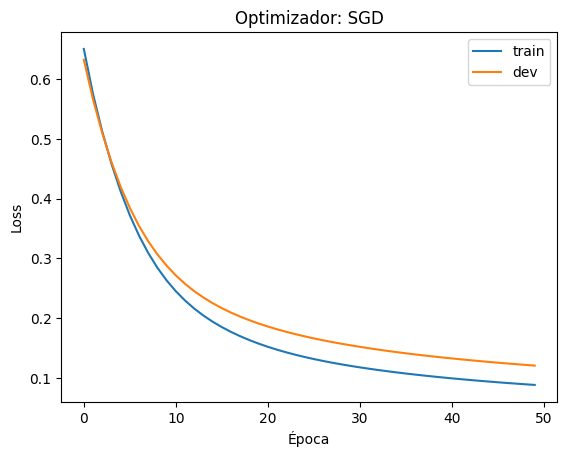

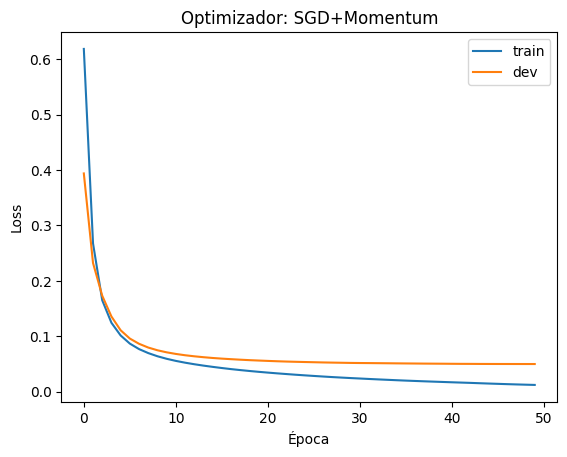

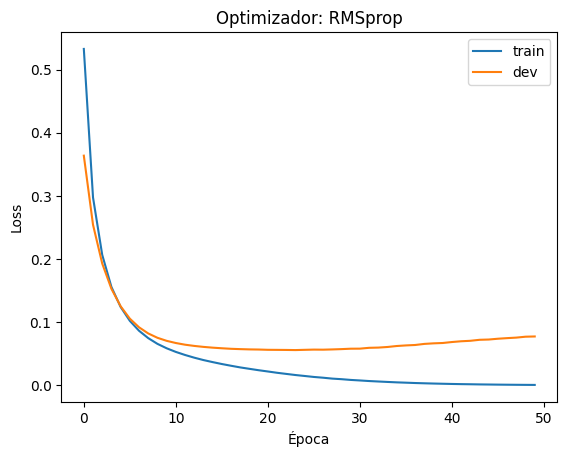

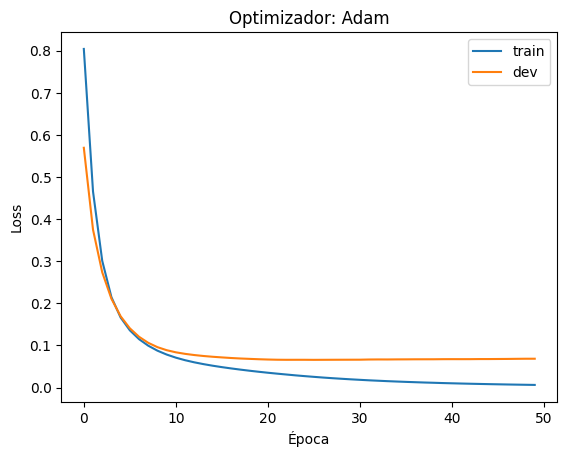

,Optimizador,Accuracy,Precision,Recall,F1
0,SGD,0.9561,0.9583,0.9718,0.9650
1,SGD+Momentum,0.9825,0.9859,0.9859,0.9859
2,RMSprop,0.9825,0.9859,0.9859,0.9859
3,Adam,0.9737,0.9857,0.9718,0.9787


In [3]:
opts = {"SGD": keras.optimizers.SGD(0.01),
        "SGD+Momentum": keras.optimizers.SGD(0.01, momentum=0.9),
        "RMSprop": keras.optimizers.RMSprop(0.001),
        "Adam": keras.optimizers.Adam(0.001)}
rows = []
for name, opt in opts.items():
    m = build_model(optimizer=opt)
    h = m.fit(X_train, y_train, validation_data=(X_dev, y_dev), epochs=50, batch_size=32, verbose=0)
    plot_history(h, f"Optimizador: {name}")
    met, _ = evaluate(m, X_dev, y_dev); rows.append({"Optimizador": name, **met})
pd.DataFrame(rows).round(4)

**Práctica B: regularización (L2, Dropout, Early Stopping)**

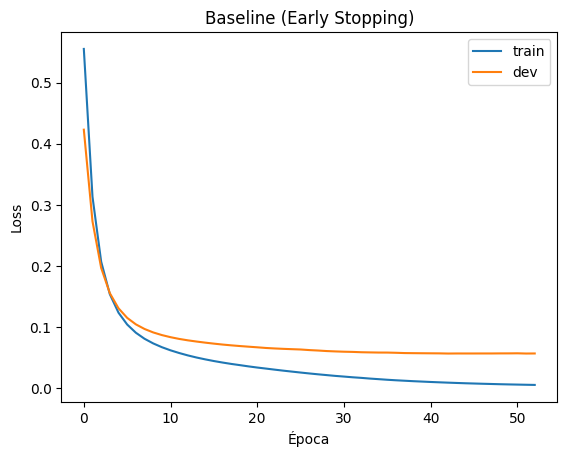

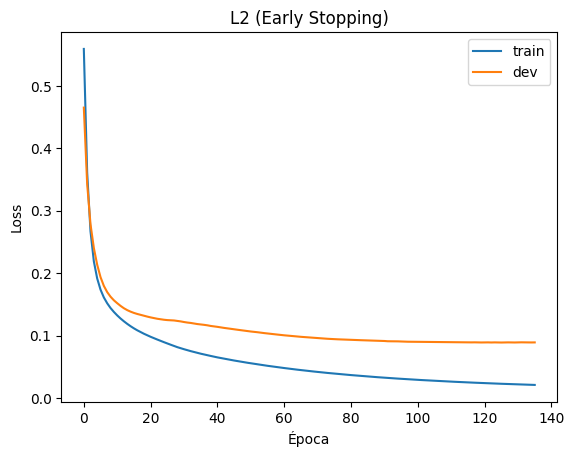

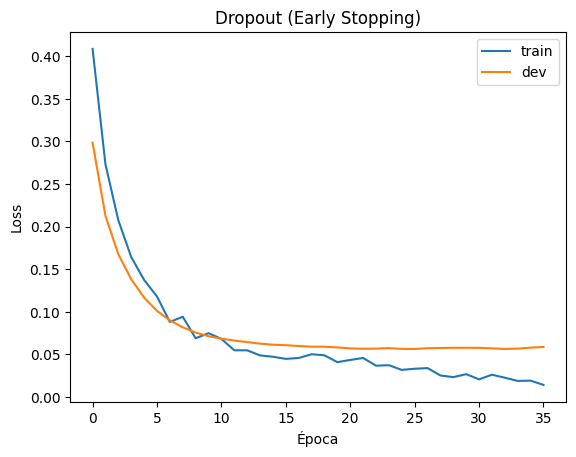

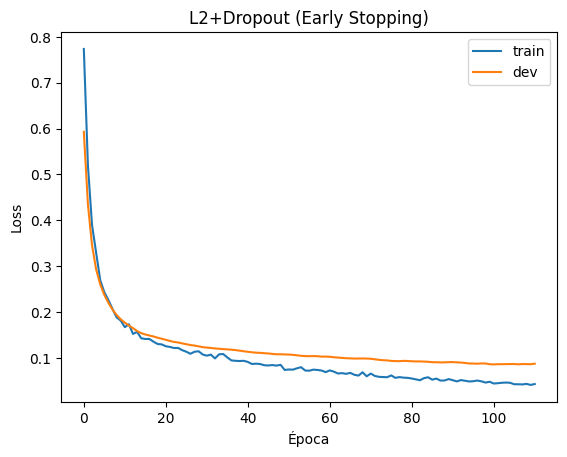

,Modelo,Acc train,Acc dev,Gap (varianza),Épocas
0,Baseline,0.9971,0.9825,0.0146,53
1,L2,1.0000,0.9737,0.0263,136
2,Dropout,0.9941,0.9825,0.0117,36
3,L2+Dropout,1.0000,0.9825,0.0175,111


In [6]:
configs = {"Baseline": dict(), "L2": dict(l2=0.001), "Dropout": dict(dropout=0.2),
           "L2+Dropout": dict(l2=0.001, dropout=0.2)}
rows, models = [], {}
for name, cfg in configs.items():
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    m = build_model(**cfg)
    h = m.fit(X_train, y_train, validation_data=(X_dev, y_dev), epochs=200,
              batch_size=32, callbacks=[es], verbose=0)
    plot_history(h, f"{name} (Early Stopping)")
    tr, _ = evaluate(m, X_train, y_train); dv, _ = evaluate(m, X_dev, y_dev)
    rows.append({"Modelo": name, "Acc train": tr["Accuracy"], "Acc dev": dv["Accuracy"],
                 "Gap (varianza)": tr["Accuracy"]-dv["Accuracy"], "Épocas": len(h.history["loss"])})
    models[name] = m
pd.DataFrame(rows).round(4)

**Práctica C: evaluación final en test**

Accuracy     0.8684
Precision    0.9385
Recall       0.8472
F1           0.8905
dtype: float64


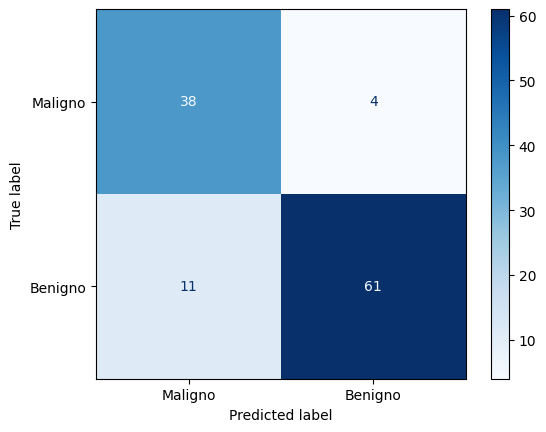

In [5]:
best = models["L2+Dropout"]   # elige según el desempeño en dev, no en test
met, pred = evaluate(best, X_test, y_test)
print(pd.Series(met).round(4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["Maligno","Benigno"]).plot(cmap="Blues"); plt.show()